<a href="https://colab.research.google.com/github/zubaeteee20210205109-droid/Thesis/blob/main/A_Hybrid_EfficientNetV2%E2%80%93Transformer_Deep_Learning_Model_for_Arsenicosis_Skin_Disease_Detection_Using_Leakage_Free_Group_Wise_Data_Splitting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [15]:
# ============================================================
# CHECK GPU
# ============================================================

import tensorflow as tf

print("="*60)
print("TensorFlow Version :", tf.__version__)
print("="*60)

print("Built with CUDA :", tf.test.is_built_with_cuda())
print("GPU Available   :", tf.test.is_gpu_available())

print("="*60)

gpus = tf.config.list_physical_devices("GPU")

print("Available GPUs :", gpus)

if gpus:

    print("\n✅ GPU DETECTED")

    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)

    print("GPU Name :", tf.config.experimental.get_device_details(gpus[0]).get("device_name"))

else:

    print("\n❌ NO GPU DETECTED")
    print("TensorFlow is running on CPU.")

print("="*60)

TensorFlow Version : 2.20.0
Built with CUDA : True
GPU Available   : True
Available GPUs : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

✅ GPU DETECTED
GPU Name : Tesla T4


In [16]:
# ============================================================
# COPY AUGMENTED DATASET TO LOCAL SSD (FIXED)
# ============================================================

import os
import shutil

SOURCE = "/content/drive/MyDrive/ArsenicSkinImage(BD)/Augmented"
DESTINATION = "/content/Augmented"

if not os.path.exists(DESTINATION):

    print("Copying Augmented dataset to local SSD...")

    shutil.copytree(
        SOURCE,
        DESTINATION
    )

    print("Dataset copied successfully to /content/Augmented ✅")

else:
    print("Dataset already exists in local SSD ✅")

Dataset already exists in local SSD ✅


In [17]:
# ============================================================
# BLOCK 3 : IMPORTS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc,
    precision_recall_curve
)

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input

In [18]:
import os
import numpy as np

DATASET_PATH = "/content/Augmented"
classes = ["infected", "not_infected"]

file_paths, labels, groups = [], [], []

for cls in classes:
    class_path = os.path.join(DATASET_PATH, cls)

    for file in os.listdir(class_path):

        if file.lower().endswith(".png"):

            full_path = os.path.join(class_path, file)
            file_paths.append(full_path)
            labels.append(cls)

            # SAFE GROUP
            group_id = file.split("_augmented")[0].split(".")[0]
            groups.append(group_id)

file_paths = np.array(file_paths)
labels = np.array(labels)
groups = np.array(groups)

NUM_CLASSES = len(classes)

print(len(file_paths), "images loaded")
print(len(set(groups)), "groups")
print("NUM_CLASSES =", NUM_CLASSES)

8892 images loaded
1482 groups
NUM_CLASSES = 2


In [19]:
from sklearn.model_selection import GroupShuffleSplit

gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)

train_idx, temp_idx = next(
    gss1.split(file_paths, labels, groups=groups)
)

train_paths = file_paths[train_idx]
train_labels = labels[train_idx]

temp_paths = file_paths[temp_idx]
temp_labels = labels[temp_idx]
temp_groups = groups[temp_idx]

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)

val_idx, test_idx = next(
    gss2.split(temp_paths, temp_labels, groups=temp_groups)
)

val_paths = temp_paths[val_idx]
val_labels = temp_labels[val_idx]

test_paths = temp_paths[test_idx]
test_labels = temp_labels[test_idx]

print(len(train_paths), len(val_paths), len(test_paths))

6222 1332 1338


In [20]:
# ============================================================
# BLOCK 6 : RESET SPLIT FOLDER (NO LEAKAGE GUARANTEE)
# ============================================================

import shutil, os

BASE_DIR = "/content/Split_Dataset"

if os.path.exists(BASE_DIR):
    shutil.rmtree(BASE_DIR)

for split in ["Train", "Validation", "Test"]:
    for cls in classes:
        os.makedirs(os.path.join(BASE_DIR, split, cls), exist_ok=True)

In [21]:
# ============================================================
# BLOCK 7 : COPY DATA SAFELY
# ============================================================

def copy_files(paths, labels, split_name):
    for p, l in zip(paths, labels):
        dest = os.path.join(BASE_DIR, split_name, l, os.path.basename(p))
        if not os.path.exists(dest):
            shutil.copy(p, dest)

copy_files(train_paths, train_labels, "Train")
copy_files(val_paths, val_labels, "Validation")
copy_files(test_paths, test_labels, "Test")

print("Copied safely")

Copied safely


In [22]:
# ============================================================
# BLOCK 8 : DATA GENERATORS
# ============================================================

IMG_SIZE = (224,224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=40,
    zoom_range=0.3,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)
test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_datagen.flow_from_directory(
    BASE_DIR + "/Train",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical"
)

val_generator = val_datagen.flow_from_directory(
    BASE_DIR + "/Validation",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical"
)

test_generator = test_datagen.flow_from_directory(
    BASE_DIR + "/Test",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

Found 6222 images belonging to 2 classes.
Found 1332 images belonging to 2 classes.
Found 1338 images belonging to 2 classes.


In [23]:
# ============================================================
# BLOCK 9 : CLASS WEIGHTS
# ============================================================

labels_list = train_generator.classes

class_weights_values = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(labels_list),
    y=labels_list
)

class_weights = dict(enumerate(class_weights_values))

print("Class Weights:")
print(class_weights)

Class Weights:
{0: np.float64(0.9838709677419355), 1: np.float64(1.0166666666666666)}


In [24]:
# ============================================================
# BLOCK 10 : TRANSFORMER BLOCK
# ============================================================

def transformer_block(x):

    attn = layers.MultiHeadAttention(
        num_heads=4,
        key_dim=x.shape[-1] // 4
    )(x, x)

    x1 = layers.Add()([x, attn])
    x1 = layers.LayerNormalization()(x1)

    ffn = layers.Dense(x.shape[-1] * 2, activation='gelu')(x1)
    ffn = layers.Dense(x.shape[-1])(ffn)

    x2 = layers.Add()([x1, ffn])
    x2 = layers.LayerNormalization()(x2)

    return x2

In [25]:
# ============================================================
# BLOCK 5 : BUILD MODEL
# ============================================================

def build_model(num_classes):

    inputs = layers.Input(shape=(224,224,3))

    base = tf.keras.applications.EfficientNetV2B0(
        include_top=False,
        weights="imagenet",
        input_tensor=inputs
    )

    base.trainable = True
    for layer in base.layers[:-20]:
        layer.trainable = False

    x = base.output

    shape = tf.keras.backend.int_shape(x)
    h, w, c = shape[1], shape[2], shape[3]

    num_patches = h * w

    x = layers.Reshape((num_patches, c))(x)

    pos = tf.range(num_patches)

    x = x + layers.Embedding(num_patches, c)(pos)

    x = transformer_block(x)
    x = transformer_block(x)

    x = layers.GlobalAveragePooling1D()(x)

    x = layers.Dense(512, activation="relu")(x)
    x = layers.Dropout(0.4)(x)

    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.3)(x)

    out = layers.Dense(num_classes, activation="softmax")(x)

    return models.Model(inputs, out)

model = build_model(NUM_CLASSES)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          0 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ normalization[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │      4,608 │ stem_activation[… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_bn  │ (None, 112, 112,  │         64 │ block1a_project_… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_ac… │ (None, 112, 112,  │          0 │ block1a_project_… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_conv │ (None, 56, 56,    │      9,216 │ block1a_project_… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_bn   │ (None, 56, 56,    │        256 │ block2a_expand_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_act… │ (None, 56, 56,    │          0 │ block2a_expand_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_project_co… │ (None, 56, 56,    │      2,048 │ block2a_expand_a… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_project_bn  │ (None, 56, 56,    │        128 │ block2a_project_… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_conv │ (None, 56, 56,    │     36,864 │ block2a_project_… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_bn   │ (None, 56, 56,    │        512 │ block2b_expand_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_act… │ (None, 56, 56,    │          0 │ block2b_expand_b

 Total params: 32,949,586 (125.69 MB)

 Trainable params: 27,848,114 (106.23 MB)

 Non-trainable params: 5,101,472 (19.46 MB)

In [26]:
# ============================================================
# BLOCK 12 : COMPILE MODEL
# ============================================================

model.compile(
    optimizer=tf.keras.optimizers.AdamW(
        learning_rate=3e-4,
        weight_decay=1e-4
    ),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [27]:
# ============================================================
# BLOCK 13 : CALLBACKS
# ============================================================

import os
import json
from tensorflow.keras import callbacks

# ------------------------------------------------------------
# SAVE DIRECTORY (Google Drive)
# ------------------------------------------------------------
SAVE_DIR = "/content/drive/MyDrive/Thesis_Model"
os.makedirs(SAVE_DIR, exist_ok=True)

# ------------------------------------------------------------
# FILE PATHS
# ------------------------------------------------------------
BEST_MODEL_PATH = os.path.join(SAVE_DIR, "Best_Model.keras")
FINAL_MODEL_PATH = os.path.join(SAVE_DIR, "Final_Model.keras")

HISTORY_PKL = os.path.join(SAVE_DIR, "history.pkl")
CSV_LOG = os.path.join(SAVE_DIR, "training_log.csv")

CLASS_INDEX_PATH = os.path.join(SAVE_DIR, "class_indices.json")

# ------------------------------------------------------------
# SAVE CLASS INDICES (IMPORTANT FOR TESTING LATER)
# ------------------------------------------------------------
with open(CLASS_INDEX_PATH, "w") as f:
    json.dump(train_generator.class_indices, f)

print("Class indices saved ✅")

# ------------------------------------------------------------
# CALLBACKS
# ------------------------------------------------------------
callbacks_list = [

    # Save best model only (based on validation accuracy)
    callbacks.ModelCheckpoint(
        filepath=BEST_MODEL_PATH,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    # Stop training when model stops improving
    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    # Reduce learning rate when stuck
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),

    # Save epoch-wise training logs (VERY IMPORTANT for curves later)
    callbacks.CSVLogger(
        CSV_LOG,
        append=False
    )
]

print("Callbacks ready ✅")

Class indices saved ✅
Callbacks ready ✅


In [28]:
# ============================================================
# BLOCK 14 : TRAIN MODEL
# ============================================================

history = model.fit(

    train_generator,

    validation_data=val_generator,

    epochs=25,

    class_weight=class_weights,

    callbacks=callbacks_list,

    verbose=1
)

Epoch 1/25
195/195 ━━━━━━━━━━━━━━━━━━━━ 0s 661ms/step - accuracy: 0.8175 - loss: 0.4535
Epoch 1: val_accuracy improved from None to 0.92342, saving model to /content/drive/MyDrive/Thesis_Model/Best_Model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Thesis_Model/Best_Model.keras
195/195 ━━━━━━━━━━━━━━━━━━━━ 235s 945ms/step - accuracy: 0.8912 - loss: 0.3115 - val_accuracy: 0.9234 - val_loss: 0.3374 - learning_rate: 3.0000e-04
Epoch 2/25
195/195 ━━━━━━━━━━━━━━━━━━━━ 0s 541ms/step - accuracy: 0.9540 - loss: 0.1617
Epoch 2: val_accuracy improved from 0.92342 to 0.95571, saving model to /content/drive/MyDrive/Thesis_Model/Best_Model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis_Model/Best_Model.keras
195/195 ━━━━━━━━━━━━━━━━━━━━ 113s 581ms/step - accuracy: 0.9574 - loss: 0.1409 - val_accuracy: 0.9557 - val_loss: 0.1294 - learning_rate: 3.0000e-04
Epoch 3/25
195/195 ━━━━━━━━━━━━━━━━━━━━ 0s 547ms/step - accuracy: 0.9625 - loss: 0.1246
Epoch 3: val_ac

In [29]:
test_loss, test_accuracy = model.evaluate(
    test_generator,
    verbose=1
)

print("\n" + "="*50)
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy*100:.2f}%")
print("="*50)

42/42 ━━━━━━━━━━━━━━━━━━━━ 16s 394ms/step - accuracy: 0.9843 - loss: 0.0556

Test Loss     : 0.0556
Test Accuracy : 98.43%


In [30]:
# ============================================================
# BLOCK 16 : PREDICTIONS
# ============================================================

import numpy as np

# Reset generator
test_generator.reset()

# Predict probabilities
y_pred_prob = model.predict(
    test_generator,
    verbose=1
)

# Predicted class
y_pred = np.argmax(y_pred_prob, axis=1)

# True class
y_true = test_generator.classes

# Class Names
class_names = list(test_generator.class_indices.keys())

print("Prediction Completed Successfully.")

42/42 ━━━━━━━━━━━━━━━━━━━━ 20s 287ms/step
Prediction Completed Successfully.


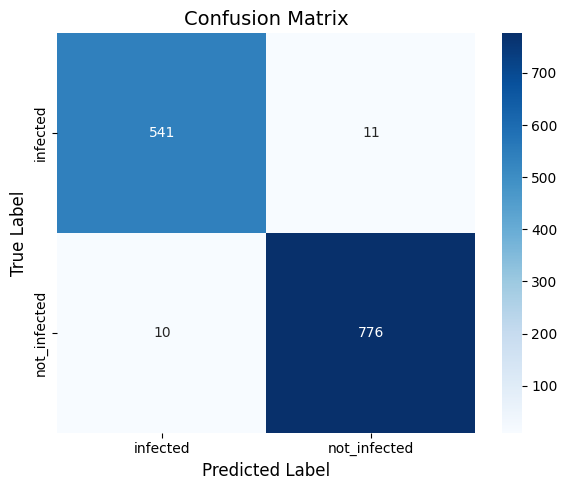

In [31]:
# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.title("Confusion Matrix", fontsize=14)

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/Thesis_Model/Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [32]:
# ============================================================
# BLOCK 18 : CLASSIFICATION REPORT
# ============================================================

print("="*60)
print("Classification Report")
print("="*60)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    average='weighted'
)

recall = recall_score(
    y_true,
    y_pred,
    average='weighted'
)

f1 = f1_score(
    y_true,
    y_pred,
    average='weighted'
)

print("\n"+"="*60)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print("="*60)

Classification Report
              precision    recall  f1-score   support

    infected     0.9819    0.9801    0.9810       552
not_infected     0.9860    0.9873    0.9866       786

    accuracy                         0.9843      1338
   macro avg     0.9839    0.9837    0.9838      1338
weighted avg     0.9843    0.9843    0.9843      1338


Accuracy : 0.9843
Precision: 0.9843
Recall   : 0.9843
F1-score : 0.9843


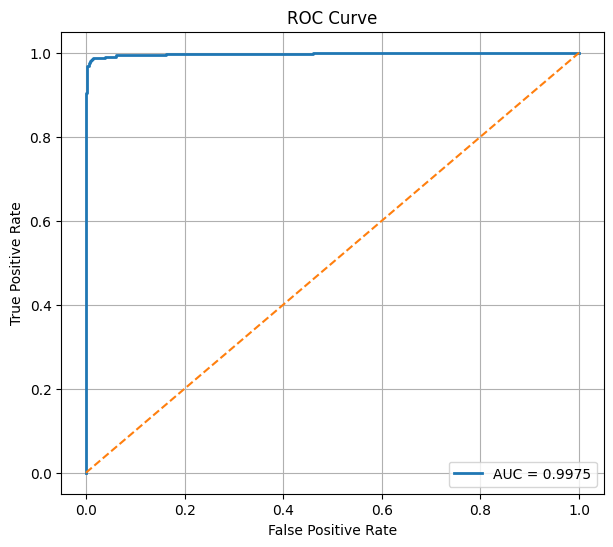

In [33]:
# ============================================================
# BLOCK 19 : ROC CURVE
# ============================================================

from sklearn.metrics import roc_curve, auc

# Positive class probability
y_score = y_pred_prob[:,1]

fpr, tpr, _ = roc_curve(y_true, y_score)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    lw=2,
    label=f"AUC = {roc_auc:.4f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle='--'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")

plt.grid(True)

plt.show()

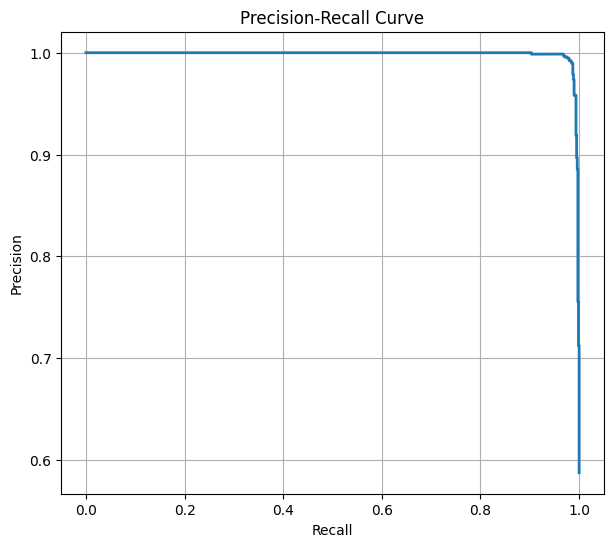

In [34]:
# ============================================================
# BLOCK 20 : PRECISION-RECALL CURVE
# ============================================================

precision_curve, recall_curve, _ = precision_recall_curve(
    y_true,
    y_score
)

plt.figure(figsize=(7,6))

plt.plot(
    recall_curve,
    precision_curve,
    linewidth=2
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")

plt.grid(True)

plt.show()

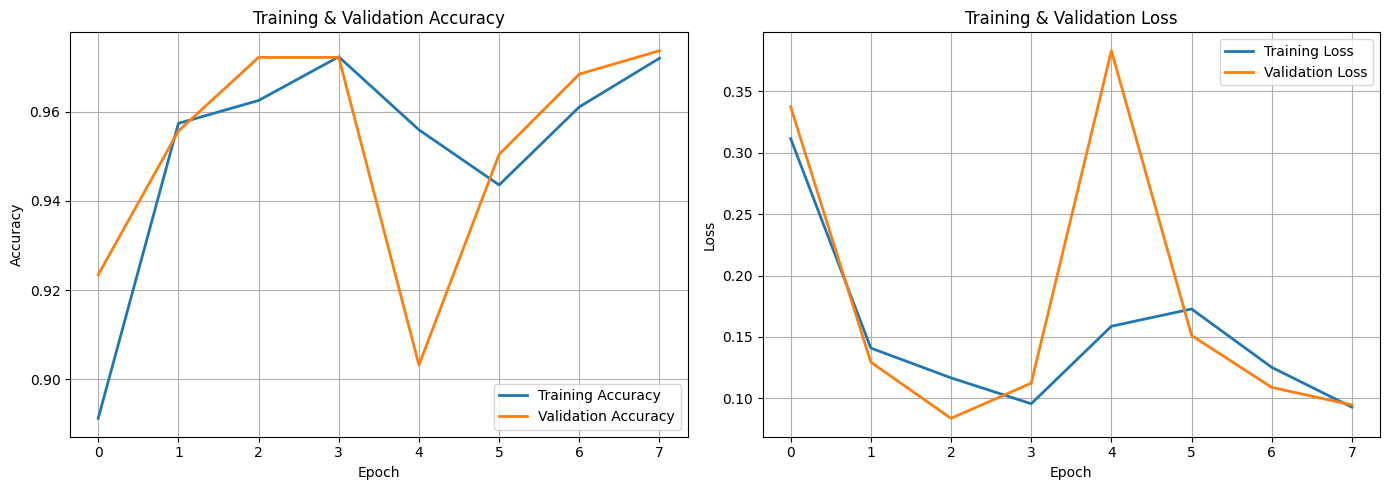

In [35]:
# ============================================================
# BLOCK 21 : TRAINING CURVES (SUBPLOTS)
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Accuracy
axes[0].plot(history.history['accuracy'], label='Training Accuracy', linewidth=2)
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)

axes[0].set_title("Training & Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss
axes[1].plot(history.history['loss'], label='Training Loss', linewidth=2)
axes[1].plot(history.history['val_loss'], label='Validation Loss', linewidth=2)

axes[1].set_title("Training & Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [36]:
# ============================================================
# BLOCK 22 : MEDICAL PERFORMANCE METRICS
# ============================================================

from sklearn.metrics import (
    confusion_matrix,
    balanced_accuracy_score,
    matthews_corrcoef,
    cohen_kappa_score
)

cm = confusion_matrix(y_true, y_pred)

TN, FP, FN, TP = cm.ravel()

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

specificity = TN / (TN + FP)

sensitivity = TP / (TP + FN)

balanced_acc = balanced_accuracy_score(
    y_true,
    y_pred
)

mcc = matthews_corrcoef(
    y_true,
    y_pred
)

kappa = cohen_kappa_score(
    y_true,
    y_pred
)

# ------------------------------------------------------------
# Print
# ------------------------------------------------------------

print("="*60)
print("Medical Evaluation Metrics")
print("="*60)

print(f"Sensitivity (Recall/TPR) : {sensitivity:.4f}")

print(f"Specificity (TNR)        : {specificity:.4f}")

print(f"Balanced Accuracy        : {balanced_acc:.4f}")

print(f"Matthews Corrcoef (MCC)  : {mcc:.4f}")

print(f"Cohen's Kappa            : {kappa:.4f}")

print("="*60)

Medical Evaluation Metrics
Sensitivity (Recall/TPR) : 0.9873
Specificity (TNR)        : 0.9801
Balanced Accuracy        : 0.9837
Matthews Corrcoef (MCC)  : 0.9676
Cohen's Kappa            : 0.9676


In [37]:
# ============================================================
# BLOCK 23 : SAVE RESULTS
# ============================================================

results = pd.DataFrame({

    "Metric":[

        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "Sensitivity",
        "Specificity",
        "Balanced Accuracy",
        "MCC",
        "Cohen Kappa",
        "Test Loss"

    ],

    "Value":[

        accuracy,
        precision,
        recall,
        f1,
        sensitivity,
        specificity,
        balanced_acc,
        mcc,
        kappa,
        test_loss

    ]

})

results.to_excel(
    "/content/drive/MyDrive/Thesis_Model/Performance_Metrics.xlsx",
    index=False
)

print(results)

              Metric     Value
0           Accuracy  0.984305
1          Precision  0.984302
2             Recall  0.984305
3           F1-score  0.984303
4        Sensitivity  0.987277
5        Specificity  0.980072
6  Balanced Accuracy  0.983675
7                MCC  0.967612
8        Cohen Kappa  0.967611
9          Test Loss  0.055648


In [38]:
print(len(set(train_generator.classes)))
print(len(set(val_generator.classes)))
print(len(set(test_generator.classes)))

2
2
2


In [44]:
train_groups = set(groups[train_idx])
val_groups = set(temp_groups[val_idx])
test_groups = set(temp_groups[test_idx])

print("Train ∩ Val:", len(train_groups & val_groups))
print("Train ∩ Test:", len(train_groups & test_groups))
print("Val ∩ Test:", len(val_groups & test_groups))

Train ∩ Val: 0
Train ∩ Test: 0
Val ∩ Test: 0


In [40]:
# ============================================================
# LEAKAGE CHECK : VERIFY GROUPS ARE DISJOINT
# ============================================================

def extract_group(path):
    filename = os.path.basename(path)
    return filename.split("_augmented")[0].split(".")[0]

train_groups = set(map(extract_group, train_paths))
val_groups = set(map(extract_group, val_paths))
test_groups = set(map(extract_group, test_paths))

train_val_overlap = train_groups & val_groups
train_test_overlap = train_groups & test_groups
val_test_overlap = val_groups & test_groups

print("="*60)
print("GROUP LEAKAGE CHECK")
print("="*60)

print(f"Train Groups      : {len(train_groups)}")
print(f"Validation Groups : {len(val_groups)}")
print(f"Test Groups       : {len(test_groups)}")

print("\nOverlapping Groups")
print("--------------------------")
print("Train ∩ Validation :", len(train_val_overlap))
print("Train ∩ Test       :", len(train_test_overlap))
print("Validation ∩ Test  :", len(val_test_overlap))

if (
    len(train_val_overlap) == 0 and
    len(train_test_overlap) == 0 and
    len(val_test_overlap) == 0
):
    print("\n✅ SUCCESS: No group leakage detected!")
else:
    print("\n❌ WARNING: Leakage detected!")
    print("Train-Val:", train_val_overlap)
    print("Train-Test:", train_test_overlap)
    print("Val-Test:", val_test_overlap)

GROUP LEAKAGE CHECK
Train Groups      : 1037
Validation Groups : 222
Test Groups       : 223

Overlapping Groups
--------------------------
Train ∩ Validation : 0
Train ∩ Test       : 0
Validation ∩ Test  : 0

✅ SUCCESS: No group leakage detected!


In [41]:
# ============================================================
# DUPLICATE FILE CHECK
# ============================================================

train_files = set(map(os.path.basename, train_paths))
val_files = set(map(os.path.basename, val_paths))
test_files = set(map(os.path.basename, test_paths))

print("="*60)
print("FILE DUPLICATE CHECK")
print("="*60)

print("Train ∩ Validation :", len(train_files & val_files))
print("Train ∩ Test       :", len(train_files & test_files))
print("Validation ∩ Test  :", len(val_files & test_files))

if (
    len(train_files & val_files) == 0 and
    len(train_files & test_files) == 0 and
    len(val_files & test_files) == 0
):
    print("\n✅ No duplicate files found.")
else:
    print("\n❌ Duplicate files detected.")

FILE DUPLICATE CHECK
Train ∩ Validation : 0
Train ∩ Test       : 0
Validation ∩ Test  : 0

✅ No duplicate files found.


In [42]:
# ============================================================
# VERIFY COPIED SPLITS
# ============================================================

import os

def get_files(folder):
    files = set()
    for root, _, filenames in os.walk(folder):
        for f in filenames:
            files.add(f)
    return files

train = get_files(BASE_DIR + "/Train")
val = get_files(BASE_DIR + "/Validation")
test = get_files(BASE_DIR + "/Test")

print("="*60)
print("COPIED DATASET CHECK")
print("="*60)

print("Train images      :", len(train))
print("Validation images :", len(val))
print("Test images       :", len(test))

print("Train ∩ Validation :", len(train & val))
print("Train ∩ Test       :", len(train & test))
print("Validation ∩ Test  :", len(val & test))

if (
    len(train & val) == 0 and
    len(train & test) == 0 and
    len(val & test) == 0
):
    print("\n✅ Copied dataset is completely leakage-free.")
else:
    print("\n❌ Leakage found in copied dataset.")

COPIED DATASET CHECK
Train images      : 6222
Validation images : 1332
Test images       : 1338
Train ∩ Validation : 0
Train ∩ Test       : 0
Validation ∩ Test  : 0

✅ Copied dataset is completely leakage-free.
